# GARCH(1,1): прогноз волатильности, VaR и бэктестинг

Исследуем дневные цены Сбербанка (SBER). Сравним GARCH с нормальными ошибками,
GARCH со стандартизированными ошибками Стьюдента и исторический VaR.
Уровни доверия: **95% и 99%**, горизонт: **следующее торговое наблюдение**.

**Порядок:** данные → EDA на обучающем периоде → модель → последовательные прогнозы → бэктестинг → ES → выводы.
Доходности и риск выражены в процентных пунктах. Отрицательная граница доходности отличается знаком от VaR убытка.
Выберите окружение `.venv` в правом верхнем углу VS Code и выполните **Run All**.

In [1]:
from pathlib import Path
import sys
import json
import platform
import importlib.metadata
from datetime import datetime, timezone

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'AGENTS.md').exists() and (p / 'src/garch_var').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from garch_var.data import download_moex, read_prices, log_returns, quality_report, sha256
from garch_var.analysis import stationarity, residual_diagnostics, eda_figure, correlation_figure, backtest_figure, conclusions
from garch_var.model import fit_garch, forecast_one, walk_forward, historical_forecasts
from garch_var.backtest import summarize

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.18})
pd.set_option('display.max_columns', 24)
print('Python:', sys.version.split()[0], '| interpreter:', sys.executable)

Python: 3.13.9 | interpreter: <project>


## 1. Настройки и источник

Базовый период — 2016–2025, последние 500 доходностей оставляем для бэктеста.
Период фиксирован для воспроизводимости; это историческое исследование, а не актуальная торговая рекомендация.
Котировки скачиваются с MOEX ISS только при отсутствии локального снимка. При повторном запуске проверяется контрольная сумма.

Для Kaggle скачайте CSV и задайте `CSV_PATH`, имена столбцов и `SOURCE_URL`. Данные должны относиться к одному активу и одному наблюдению в день.
Пример найденного набора: [RUSSIA 249 Stocks Prices MOEX](https://www.kaggle.com/datasets/olegshpagin/russia-stocks-prices-ohlcv).
Основной источник здесь — Мосбиржа: доступен прямой запрос одного актива вместо загрузки большого набора разных частот.

In [2]:
TICKER = 'SBER'
START, END = '2016-01-01', '2025-12-31'
TEST_SIZE = 500
LEVELS = (0.95, 0.99)
DISTRIBUTIONS = ('normal', 't')
CSV_PATH = None  # например ROOT / 'data/raw/SBER_D1.csv'
DATE_COLUMN, PRICE_COLUMN, CSV_SEPARATOR = 'datetime', 'close', ','
SOURCE_URL = None  # ссылка на набор Kaggle при использовании CSV

if CSV_PATH is None:
    data_path, manifest = download_moex(ROOT, TICKER, START, END)
    prices = read_prices(data_path)
else:
    if not SOURCE_URL:
        raise ValueError('Укажите SOURCE_URL для импортируемого CSV.')
    data_path = Path(CSV_PATH)
    prices = read_prices(data_path, DATE_COLUMN, PRICE_COLUMN, CSV_SEPARATOR).loc[START:END]
    manifest = {'source': SOURCE_URL, 'input_file': data_path.name, 'sha256': sha256(data_path),
                'date_column': DATE_COLUMN, 'price_column': PRICE_COLUMN,
                'adjustment': 'Проверить корректировки по описанию исходного CSV.'}

returns = log_returns(prices)
if TEST_SIZE <= 0 or len(returns) - TEST_SIZE < 252:
    raise ValueError('Оставьте минимум 252 наблюдения для обучения.')
train, test = returns.iloc[:-TEST_SIZE], returns.iloc[-TEST_SIZE:]
run_id = 'notebook_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT = ROOT / 'outputs/runs' / run_id
OUT.mkdir(parents=True, exist_ok=False)
quality = quality_report(prices)
display(pd.Series(quality, name='Контроль качества'))
display(prices.head())
display(pd.DataFrame({'выборка': ['обучение', 'бэктест'], 'начало': [train.index[0], test.index[0]],
                      'конец': [train.index[-1], test.index[-1]], 'наблюдений': [len(train), len(test)]}))

observations                                                                     2577
start                                                                      2016-01-04
end                                                                        2025-12-30
missing_close                                                                       0
duplicates                                                                          0
gaps_over_7_calendar_days                    [{'date': '2022-03-24', 'gap_days': 27}]
absolute_log_returns_over_15_pct    {'2018-04-09': -18.68496307341516, '2022-02-21...
policy                              Не заполняем неторговые дни; не удаляем экстре...
Name: Контроль качества, dtype: object

,close
date,
2016-01-04,98.01
2016-01-05,98.89
2016-01-06,96.85
2016-01-11,91.03
2016-01-12,91.71


,выборка,начало,конец,наблюдений
0,обучение,2016-01-05,2024-04-17,2076
1,бэктест,2024-04-18,2025-12-30,500


### Доходности и качество

\(r_t=100\ln(P_t/P_{t-1})\). Например, значение `-2` означает логарифмическую доходность −2 процентных пункта.
Неторговые дни не заполняются. Дубликаты, пропуски цен и неположительные цены вызывают ошибку.
Аномальные доходности сохраняются. Большие перерывы показаны в отчёте качества: доходность после остановки торгов охватывает весь перерыв.
MOEX close не корректируется на дивиденды; дивидендные разрывы влияют на оценку риска цены и отличаются от полной доходности инвестора.

## 2. EDA: только обучающий период

Графики и тесты этого раздела не используют отложенные наблюдения для выбора модели.
ADF: нулевая гипотеза — единичный корень. KPSS: нулевая гипотеза — стационарность вокруг константы.
ARCH-LM: нулевая гипотеза — отсутствие ARCH-эффекта до выбранного лага.

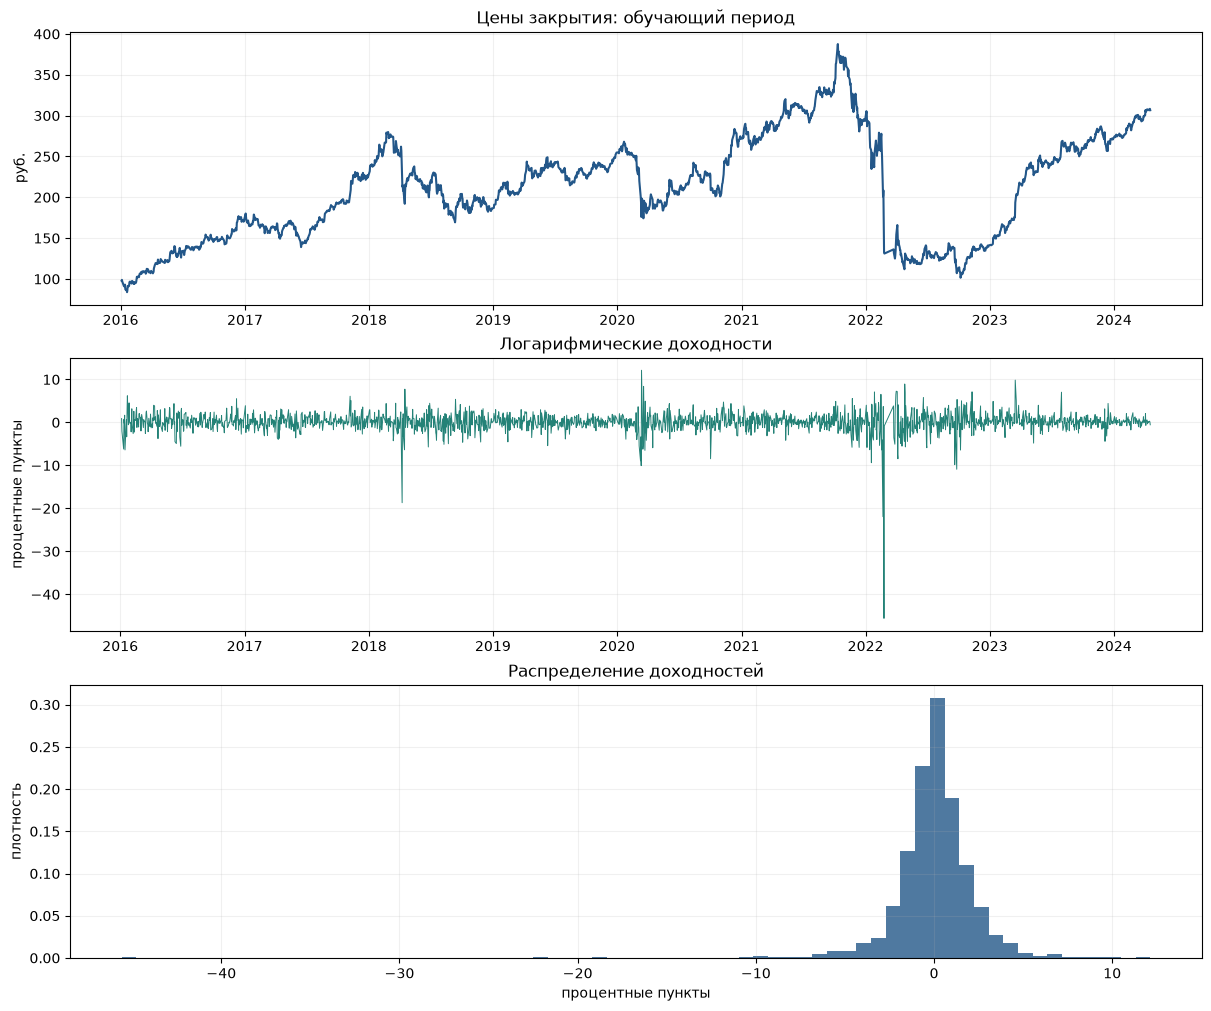

,"доходности, п.п."
count,2076.000000
mean,0.054935
std,2.267087
min,-45.591829
25%,-0.819693
50%,0.072016
75%,1.075972
max,12.132025


,test,null_hypothesis,statistic,p_value,lags,note
0,ADF,Единичный корень (нестационарность),-16.197975,4.105413e-29,8,
1,KPSS,Стационарность вокруг константы,0.118440,1.000000e-01,10,The test statistic is outside of the range of ...
2,ARCH-LM,Нет ARCH-эффекта до лага 10,109.099982,8.102686e-19,10,


ADF: H0 «Единичный корень (нестационарность)» отвергается при 5%, p=4.105e-29
KPSS: H0 «Стационарность вокруг константы» не отвергается при 5%, p=0.1
ARCH-LM: H0 «Нет ARCH-эффекта до лага 10» отвергается при 5%, p=8.103e-19


In [3]:
eda_figure(prices.loc[:train.index[-1]], train).savefig(OUT / 'eda.png', dpi=140)
plt.show()
display(train.describe().to_frame('доходности, п.п.'))
tests = stationarity(train)
display(tests)
for _, row in tests.iterrows():
    decision = 'отвергается' if row.p_value < 0.05 else 'не отвергается'
    print(f'{row.test}: H0 «{row.null_hypothesis}» {decision} при 5%, p={row.p_value:.4g}')
tests.to_csv(OUT / 'stationarity.csv', index=False)

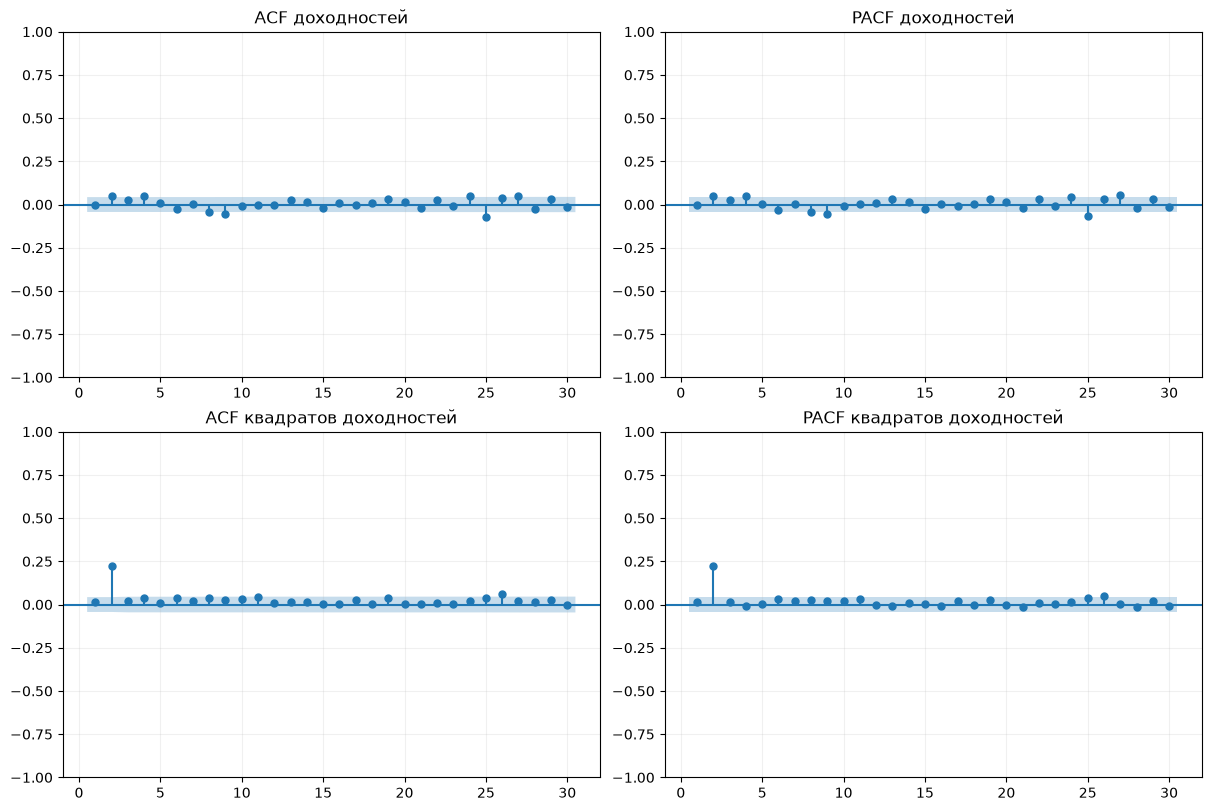

In [4]:
correlation_figure(train).savefig(OUT / 'correlations.png', dpi=140)
plt.show()

Зависимость квадратов доходностей при слабой зависимости самих доходностей согласуется с кластеризацией волатильности.
ACF/PACF и ARCH-LM рассматриваются совместно; график сам по себе не доказывает пригодность GARCH.

## 3. Обучение GARCH(1,1)

\(r_t=\mu+\epsilon_t,\quad \epsilon_t=\sigma_t z_t\),
\(\sigma_t^2=\omega+a\epsilon_{t-1}^2+b\sigma_{t-1}^2\).
Для ошибок Стьюдента используется распределение с единичной дисперсией.
Сумма \(a+b\), близкая к единице, показывает высокую устойчивость шоков; при \(a+b\ge1\) конечная безусловная дисперсия стандартной модели не существует.
Проверяем сходимость и зависимости стандартизированных остатков.


Распределение: normal
                     Constant Mean - GARCH Model Results                      
Dep. Variable:             return_pct   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -4170.74
Distribution:                  Normal   AIC:                           8349.48
Method:            Maximum Likelihood   BIC:                           8372.04
                                        No. Observations:                 2076
Date:                Wed, Oct 28 2026   Df Residuals:                     2075
Time:                        22:23:09   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1384  3.310e-02      4.1

,series,test,lag,statistic,p_value
0,residuals,Ljung-Box,10,4.295460,0.933036
1,residuals,Ljung-Box,20,7.516313,0.994615
2,squared_residuals,Ljung-Box,10,5.017547,0.890003
3,squared_residuals,Ljung-Box,20,9.428803,0.977388
4,residuals,ARCH-LM,10,4.964190,0.893557



Распределение: t
                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   return_pct   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -4012.90
Distribution:      Standardized Student's t   AIC:                           8035.79
Method:                  Maximum Likelihood   BIC:                           8063.98
                                              No. Observations:                 2076
Date:                      Wed, Oct 28 2026   Df Residuals:                     2075
Time:                              22:23:09   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
-------------------------------------------------------------------

,series,test,lag,statistic,p_value
0,residuals,Ljung-Box,10,4.306176,0.932480
1,residuals,Ljung-Box,20,7.487262,0.994753
2,squared_residuals,Ljung-Box,10,4.957216,0.894018
3,squared_residuals,Ljung-Box,20,9.567904,0.975348
4,residuals,ARCH-LM,10,4.895806,0.898029


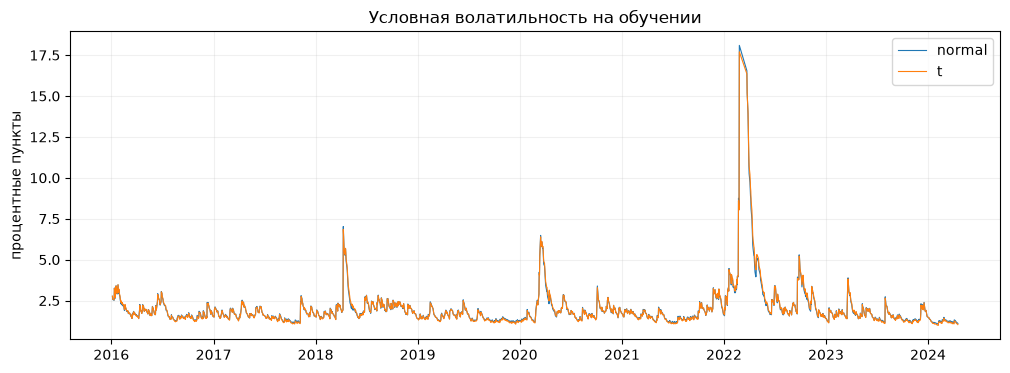

In [5]:
initial_fits = {}
for distribution in DISTRIBUTIONS:
    fit = fit_garch(train, distribution)
    initial_fits[distribution] = fit
    print(f'\nРаспределение: {distribution}')
    print(fit.summary())
    persistence = fit.params['alpha[1]'] + fit.params['beta[1]']
    print(f'alpha + beta = {persistence:.6f}')
    if persistence >= 1:
        print('Условие конечной безусловной дисперсии не выполнено.')
    diagnostics = residual_diagnostics(fit)
    display(diagnostics)
    diagnostics.to_csv(OUT / f'residual_diagnostics_{distribution}.csv', index=False)
    (OUT / f'initial_fit_{distribution}.txt').write_text(str(fit.summary()), encoding='utf-8')

fig, ax = plt.subplots(figsize=(12, 4))
for name, fit in initial_fits.items():
    ax.plot(fit.conditional_volatility, label=name, linewidth=0.8)
ax.set(title='Условная волатильность на обучении', ylabel='процентные пункты')
ax.legend()
fig.savefig(OUT / 'conditional_volatility.png', dpi=140)
plt.show()

## 4. VaR и прогноз на один шаг

Пусть \(c\) — уровень доверия и \(\alpha=1-c\). Нижняя граница доходности:
\(q_{t+1,\alpha}=\hat\mu_{t+1}+\hat\sigma_{t+1}F^{-1}(\alpha)\).
При нормальных ошибках это \(\mu-Z_c\sigma\), где \(Z_c>0\).
**Нарушение:** \(r_{t+1}<q_{t+1,\alpha}\). **VaR убытка:** \(-q_{t+1,\alpha}\).

Для каждого следующего наблюдения модель заново обучается на расширяющейся истории.
Доходность проверяемого дня не участвует в его прогнозе. Дата `origin` — последнее известное наблюдение, индекс — дата проверки.
Исторический VaR использует ту же доступную историю. Ошибки сходимости останавливают расчёт, а не исчезают из статистики.

In [6]:
parts = []
for distribution in DISTRIBUTIONS:
    parts.append(walk_forward(returns, TEST_SIZE, distribution, LEVELS, progress=print))
parts.append(historical_forecasts(returns, TEST_SIZE, LEVELS))
predictions = pd.concat(parts)
assert (pd.to_datetime(predictions.origin).to_numpy() < predictions.index.to_numpy()).all()
predictions.to_csv(OUT / 'predictions.csv')
display(predictions.head())

normal: 50/500


normal: 100/500


normal: 150/500


normal: 200/500


normal: 250/500


...

t: 350/500


t: 400/500


t: 450/500


t: 500/500


,model,origin,train_n,mu_pct,variance_pct2,sigma_pct,omega,alpha1,beta1,convergence_flag,nu,q_95_pct,var_95_loss_pct,es_95_loss_pct,q_99_pct,var_99_loss_pct,es_99_loss_pct,actual_pct
date,,,,,,,,,,,,,,,,,,
2024-04-18,GARCH-normal,2024-04-17,2076,0.138385,1.243457,1.115104,0.168140,0.130233,0.835058,0.0,NaN,-1.695798,1.695798,2.161754,-2.455735,2.455735,2.833606,0.455596
2024-04-19,GARCH-normal,2024-04-18,2077,0.138709,1.214746,1.102155,0.166720,0.130146,0.835530,0.0,NaN,-1.674174,1.674174,2.134720,-2.425287,2.425287,2.798770,-0.198255
2024-04-22,GARCH-normal,2024-04-19,2078,0.138396,1.191564,1.091588,0.165351,0.130082,0.835972,0.0,NaN,-1.657106,1.657106,2.113236,-2.401017,2.401017,2.770919,2.445613
2024-04-23,GARCH-normal,2024-04-22,2079,0.140803,1.872884,1.368534,0.170664,0.130351,0.834239,0.0,NaN,-2.110234,2.110234,2.682089,-3.042882,3.042882,3.506632,-2.442359
2024-04-24,GARCH-normal,2024-04-23,2080,0.138543,2.623827,1.619823,0.174797,0.131519,0.832198,0.0,NaN,-2.525829,2.525829,3.202687,-3.629729,3.629729,4.178632,0.178766


## 5. Бэктестинг: доходности и нарушения

На графиках показаны отрицательные границы доходности. При 95% доверии ожидаемая частота нарушений — 5%, при 99% — 1%.
Это ожидаемые частоты, а не требование точного числа нарушений в конечной выборке.

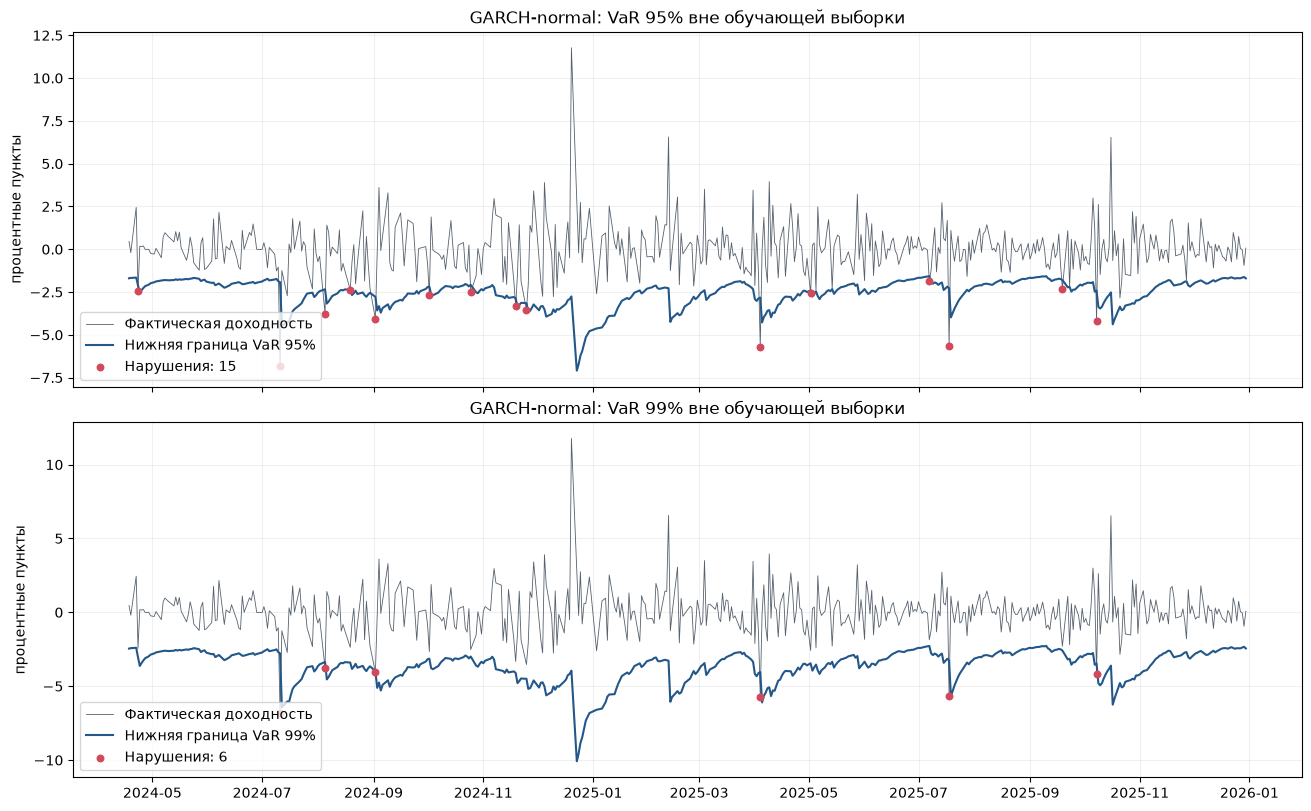

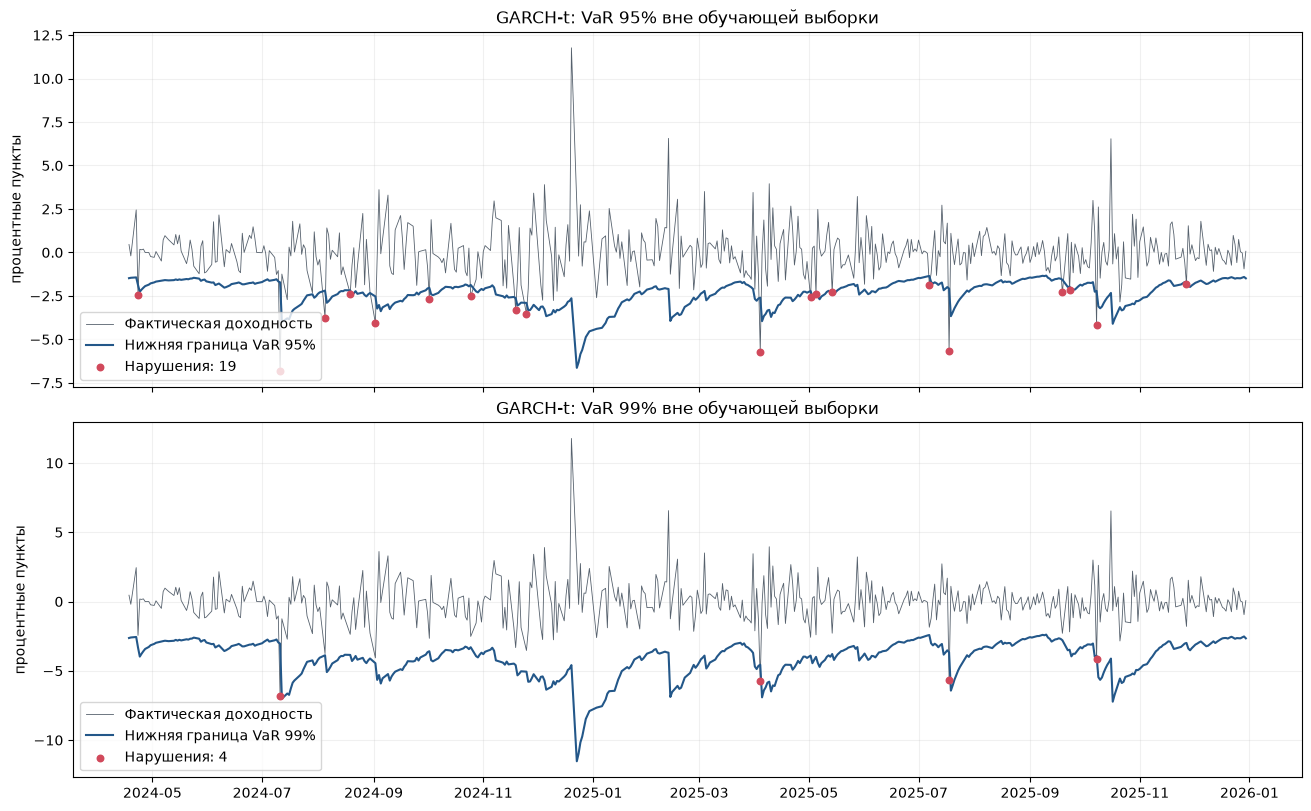

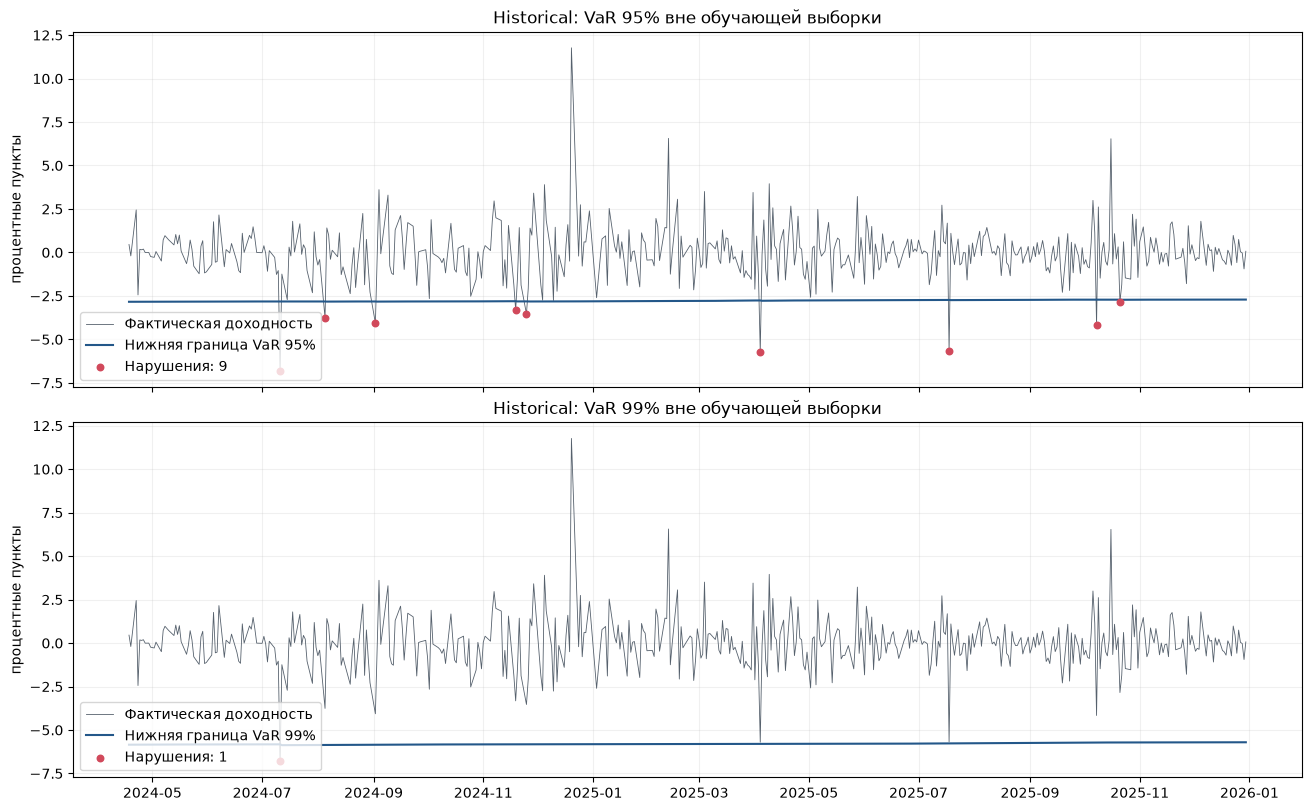

,model,confidence,n,exceptions,expected,exception_rate,kupiec_p,binomial_exact_p,independence_p,conditional_coverage_p,quantile_loss
0,GARCH-normal,0.95,500,15,25.0,0.030,0.027102,0.039501,0.334889,0.054634,0.161710
1,GARCH-normal,0.99,500,6,5.0,0.012,0.663016,0.647653,0.702341,0.845384,0.054238
2,GARCH-t,0.95,500,19,25.0,0.038,0.199385,0.258087,0.219971,0.206859,0.158731
3,GARCH-t,0.99,500,4,5.0,0.008,0.641435,0.823649,0.799296,0.868699,0.054511
4,Historical,0.95,500,9,25.0,0.018,0.000169,0.000299,0.565288,0.000720,0.168168
5,Historical,0.99,500,1,5.0,0.002,0.028240,0.070857,0.949470,0.089933,0.059822


In [7]:
for model in predictions.model.unique():
    backtest_figure(predictions, model, LEVELS).savefig(OUT / f'backtest_{model}.png', dpi=140)
    plt.show()
summary = summarize(predictions, LEVELS)
display(summary[['model', 'confidence', 'n', 'exceptions', 'expected', 'exception_rate',
                 'kupiec_p', 'binomial_exact_p', 'independence_p', 'conditional_coverage_p', 'quantile_loss']])
summary.to_csv(OUT / 'backtest_summary.csv', index=False)

Тест Купика оценивает соответствие частоты нарушений заданной вероятности. Тест Кристофферсена — зависимость соседних нарушений;
также сохранён совместный тест условного покрытия. Малый p-value (ниже 0.05) — свидетельство против соответствующей нулевой гипотезы.
Большой p-value не доказывает качество. Если один из типов предыдущего состояния не наблюдался, тест независимости не определён (`NaN`).
Для редких нарушений полезен точный биномиальный тест, а асимптотические результаты требуют осторожности.
`quantile_loss` — средняя квантильная потеря (меньше лучше), для сравнения при одинаковом уровне и наборе дат.

## 6. Expected Shortfall

ES оценивает средний условный убыток в нижнем хвосте модели и превышает VaR убытка.
Для Стьюдента учтена стандартизация до единичной дисперсии. Отдельно показываем фактический средний убыток в дни нарушения.
Сравнение этих средних — описание хвоста, а не полноценный бэктест ES; нарушений на уровне 99% может быть мало.

In [8]:
display(summary[['model', 'confidence', 'exceptions', 'realized_tail_loss_pct', 'mean_predicted_es_on_hits_pct']])
next_forecasts = pd.DataFrame([forecast_one(returns, d, LEVELS) for d in DISTRIBUTIONS])
display(Markdown('### Прогноз после последнего наблюдения'))
display(next_forecasts[['model', 'origin', 'mu_pct', 'sigma_pct', 'variance_pct2',
                        'q_95_pct', 'var_95_loss_pct', 'es_95_loss_pct',
                        'q_99_pct', 'var_99_loss_pct', 'es_99_loss_pct']])
next_forecasts.to_csv(OUT / 'next_observation_forecast.csv', index=False)
print('Это прогноз на следующее наблюдение после конца выбранной истории, без проверки на будущей фактической доходности.')

,model,confidence,exceptions,realized_tail_loss_pct,mean_predicted_es_on_hits_pct
0,GARCH-normal,0.95,15,3.582555,2.964485
1,GARCH-normal,0.99,6,5.027531,4.009645
2,GARCH-t,0.95,19,3.284652,3.165038
3,GARCH-t,0.99,4,5.585126,5.237515
4,Historical,0.95,9,4.429618,5.185724
5,Historical,0.99,1,6.797163,10.372193


### Прогноз после последнего наблюдения

,model,origin,mu_pct,sigma_pct,variance_pct2,q_95_pct,var_95_loss_pct,es_95_loss_pct,q_99_pct,var_99_loss_pct,es_99_loss_pct
0,GARCH-normal,2025-12-30,0.103667,1.070377,1.145707,-1.656946,1.656946,2.104213,-2.386402,2.386402,2.749117
1,GARCH-t,2025-12-30,0.076764,1.004736,1.009494,-1.445399,1.445399,2.196665,-2.581645,2.581645,3.602902


Это прогноз на следующее наблюдение после конца выбранной истории, без проверки на будущей фактической доходности.


## 7. Выводы и сохранение результатов

Выводы ниже формируются из фактически рассчитанной статистики. Смена распределения — сравнение заранее заданных спецификаций;
если по тестовому периоду выбирать лучшую модель, для независимой финальной оценки потребуется новая выборка.
Прогноз после последней даты исторической выборки не является актуальным прогнозом на сегодня.

In [9]:
report = conclusions(summary)
display(Markdown(report))
(OUT / 'REPORT.md').write_text(report, encoding='utf-8')
manifest['quality'] = quality
manifest['python'] = platform.python_version()
manifest['versions'] = {name: importlib.metadata.version(name) for name in ['arch', 'numpy', 'pandas', 'scipy', 'statsmodels', 'matplotlib']}
(OUT / 'data_manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
settings = {'ticker': TICKER, 'start': START, 'end': END, 'test_size': TEST_SIZE, 'levels': LEVELS,
            'distributions': DISTRIBUTIONS, 'window': 'expanding', 'refit': 'every observation',
            'train_end': str(train.index[-1].date()), 'return_unit': 'percentage points',
            'source': 'MOEX' if CSV_PATH is None else str(CSV_PATH)}
(OUT / 'settings.json').write_text(json.dumps(settings, ensure_ascii=False, indent=2), encoding='utf-8')
returns.to_csv(OUT / 'returns.csv')
print('Результаты сохранены:', OUT)

# Результаты бэктестинга

VaR показан как нижняя граница доходности; нарушение означает доходность ниже этой границы.

- GARCH-normal, 95%: 15 нарушений из 500 (3.00%), ожидается 25.0. Тест Купика отвергает соответствие частоты на уровне 5% (p = 0.0271). Тест независимости: p-value = 0.3349.
- GARCH-normal, 99%: 6 нарушений из 500 (1.20%), ожидается 5.0. Тест Купика не отвергает соответствие частоты на уровне 5% (p = 0.6630). Тест независимости: p-value = 0.7023.
- GARCH-t, 95%: 19 нарушений из 500 (3.80%), ожидается 25.0. Тест Купика не отвергает соответствие частоты на уровне 5% (p = 0.1994). Тест независимости: p-value = 0.2200.
- GARCH-t, 99%: 4 нарушений из 500 (0.80%), ожидается 5.0. Тест Купика не отвергает соответствие частоты на уровне 5% (p = 0.6414). Тест независимости: p-value = 0.7993.
- Historical, 95%: 9 нарушений из 500 (1.80%), ожидается 25.0. Тест Купика отвергает соответствие частоты на уровне 5% (p = 0.0002). Тест независимости: p-value = 0.5653.
- Historical, 99%: 1 нарушений из 500 (0.20%), ожидается 5.0. Тест Купика отвергает соответствие частоты на уровне 5% (p = 0.0282). Тест независимости: p-value = 0.9495.

Неотвержение гипотезы не доказывает качество модели. Асимптотические тесты могут иметь малую мощность при редких нарушениях; дополнительно сохранён точный биномиальный p-value.

ES — модельное условное среднее хвостового убытка. Средний фактический убыток в дни нарушения — описательная оценка, а не полноценный тест ES. При отсутствии нарушений он не определён.

Ограничения: цены не скорректированы на дивиденды; при остановках торгов доходность между соседними наблюдениями охватывает несколько календарных дней. Результаты относятся к выбранной исторической выборке.

Результаты сохранены: <project>\outputs\runs\notebook_20261028T192307338868Z


## Источники и методические ссылки

- [MOEX ISS: справочник запросов](https://iss.moex.com/iss/reference/) — источник котировок.
- [arch: последовательные прогнозы волатильности](https://arch.readthedocs.io/en/stable/univariate/univariate_volatility_forecasting.html).
- [arch: Value-at-Risk Forecasting](https://arch.readthedocs.io/en/stable/univariate/univariate_volatility_forecasting.html#value-at-risk-forecasting).
- [statsmodels: ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html) и [KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html).

Снимки котировок локальны и исключены из Git. Перед распространением данных следует проверить условия источника.